# 02 - Time-series exploration (§5.2)

PM2.5 forecasting, Group 1. This notebook is self-contained; the same steps are packaged in `src/timeseries.py`
and run by `scripts/run_eda.py`, which also writes `results/Exploratory_temporal.csv`.
It starts from the cleaned tables in `data/processed/` (run `python scripts/run_eda.py` first).

## Setup

In [1]:
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (9, 4)

DATA_RAW, DATA_PROCESSED = Path("../data/raw"), Path("../data/processed")
PM_FILE, GEE_FILE = "pm25.csv", "gee_features_daily.csv"
TARGET = "pm25"
GAS = ["NO2", "CO", "O3"]
MET = ["temperature_celsius", "pressure_mb", "wind_u", "wind_v"]
KEY_VARS = [TARGET, "AOD"] + GAS + MET

def show_fig():
    plt.tight_layout(); plt.show()

# cleaned tables written by scripts/run_eda.py (same steps as notebook 01)
P = pd.read_csv(DATA_PROCESSED / "pm25_clean.csv", parse_dates=["date"], float_precision="round_trip")    # all valid PM2.5 readings
df = pd.read_csv(DATA_PROCESSED / "data_cleaned.csv", parse_dates=["date"], float_precision="round_trip") # matched to GEE
G = pd.read_csv(DATA_RAW / GEE_FILE, parse_dates=["date", "datetime_utc"])
print("pm25_clean:", P.shape, "| data_cleaned:", df.shape)

pm25_clean: (85362, 6) | data_cleaned: (46912, 20)


# Part 5. §5.2 Time-series exploration

**Decision gate (brief):** *"determine whether temporal validation and lag-based features are appropriate from the timestamp quality, temporal dependence, and intended forecasting scenario."*

In [2]:
panel = {s: g.set_index("date").sort_index() for s, g in df.groupby("station_id")}
daily = {s: g.asfreq("D") for s, g in panel.items()}           # modelling table, regular daily calendar per station (gaps become NaN)
panelP = {s: g.set_index("date").sort_index() for s, g in P.groupby("station_id")}      # target series, BEFORE the GEE match
dailyP = {s: g.asfreq("D") for s, g in panelP.items()}
print("timestamps are whole days (no time of day):", bool((df.date == df.date.dt.normalize()).all()))
print("duplicate timestamps per station:", int(df.duplicated(["date", "station_id"]).sum()))

timestamps are whole days (no time of day): True
duplicate timestamps per station: 0


## 5a. Timestamp regularity, daily sampling, missing dates, irregular observations per station

,target series (before GEE match),modelling table (after GEE match)
n_days,760.00,458.00
coverage,0.86,0.52
missing_days,89.50,417.00
median_gap_days,1.00,1.00
max_gap_days,32.00,31.00


GEE has a record for only 70% of the calendar days between 2016-11-21 and 2026-04-16
modelling-table calendar: 3420 days, 1120 days with no station at all


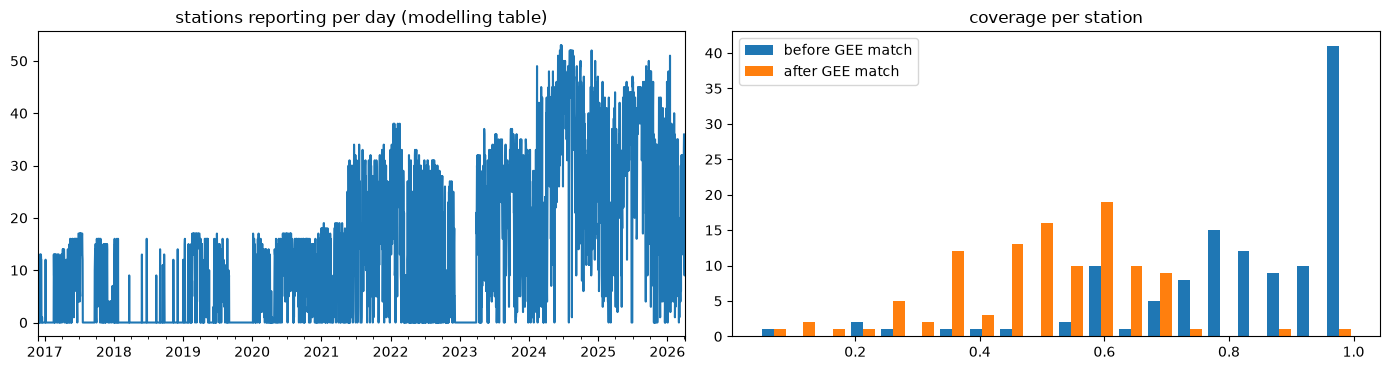

In [3]:
def reg_table(d_):
    rows = []
    for s_, g in d_.groupby("station_id"):
        d = g.date.sort_values(); gaps = d.diff().dt.days.dropna(); span = (d.max() - d.min()).days + 1
        rows.append({"station_id": s_, "first": d.min().date(), "last": d.max().date(), "n_days": len(d), "span_days": span,
                     "missing_days": span - len(d), "coverage": len(d) / span,
                     "median_gap_days": gaps.median() if len(gaps) else np.nan, "max_gap_days": gaps.max() if len(gaps) else np.nan})
    return pd.DataFrame(rows).set_index("station_id")
regularity_target = reg_table(P)         # all valid PM2.5 readings (before matching)
regularity = reg_table(df)               # the modelling table (after matching to GEE)
cols_ = ["n_days", "coverage", "missing_days", "median_gap_days", "max_gap_days"]
display(pd.DataFrame({"target series (before GEE match)": regularity_target[cols_].median(),
                      "modelling table (after GEE match)": regularity[cols_].median()}).round(2))
span_days = pd.date_range(P.date.min(), P.date.max())
gee_share = pd.Series(span_days).isin(set(G.date)).mean()
print(f"GEE has a record for only {gee_share*100:.0f}% of the calendar days between {P.date.min().date()} and {P.date.max().date()}")

all_days = pd.date_range(df.date.min(), df.date.max())
per_day = df.groupby("date").size().reindex(all_days, fill_value=0)
print(f"modelling-table calendar: {len(all_days)} days, {int((per_day == 0).sum())} days with no station at all")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
per_day.plot(ax=ax[0], title="stations reporting per day (modelling table)")
ax[1].hist([regularity_target.coverage, regularity.coverage], bins=20, label=["before GEE match", "after GEE match"]); ax[1].legend(); ax[1].set_title("coverage per station")
show_fig()

Stations report **daily**, but irregularly. Two sources of gaps: stations start and stop (the network grows over time), and, after the match to GEE, the satellite/reanalysis table has **no record for a large share of calendar days**, which breaks the modelling series into short runs. Consequences: every temporal feature must be built on a regular daily calendar per station and **never across a gap** (see `src/features.py`), and the target's autocorrelation is best studied on the full target series (before the GEE match).

## 5b. Autocorrelation and stationarity: ACF, PACF, Ljung-Box, ADF

Per station, on the **target series before the GEE match** (all valid PM2.5 readings). The ACF at lag k pairs a day with the day k earlier **without crossing gaps** (pairs with a missing day are skipped). ADF and Ljung-Box need an unbroken series, so they use each station's **longest run of consecutive days**.

,1,2,3,4,5,6,7
25%,0.570,0.332,0.213,0.148,0.114,0.085,0.067
50%,0.647,0.402,0.296,0.223,0.197,0.165,0.131
75%,0.715,0.491,0.395,0.314,0.260,0.229,0.203


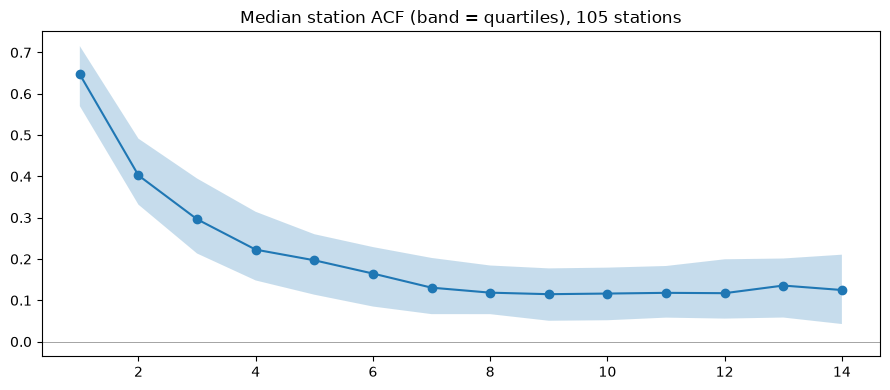

76 stations with a run of >= 60 consecutive days (median run 196 days)
ADF: stationary (p < 0.05) at 92% of these stations
Ljung-Box lag 7: autocorrelation present (p < 0.05) at 99% of these stations


In [4]:
elig = [s_ for s_, g in P.groupby("station_id") if len(g) >= 100]
acf_tab = pd.DataFrame({s_: [dailyP[s_][TARGET].corr(dailyP[s_][TARGET].shift(k)) for k in range(1, 15)] for s_ in elig}, index=range(1, 15)).T
acf_sum = acf_tab.describe().T[["25%", "50%", "75%"]]
display(acf_sum.head(7).round(3).T)
ax = acf_sum["50%"].plot(marker="o", title=f"Median station ACF (band = quartiles), {len(elig)} stations")
ax.fill_between(acf_sum.index, acf_sum["25%"], acf_sum["75%"], alpha=.25); ax.axhline(0, c="grey", lw=.5); show_fig()

def longest_run(dates):
    d = pd.Series(sorted(dates)); grp = (d.diff().dt.days != 1).cumsum()
    runs = d.groupby(grp).agg(["min", "max", "size"]); r = runs.loc[runs["size"].idxmax()]
    return r["min"], r["max"], int(r["size"])

tests = []
for s_ in elig:
    a, b, n = longest_run(panelP[s_].index)
    if n >= 60:
        x = panelP[s_].loc[a:b, TARGET]
        tests.append({"station_id": s_, "run_days": n, "adf_p": adfuller(x, autolag="AIC")[1], "ljungbox_p_lag7": acorr_ljungbox(x, lags=[7]).lb_pvalue.iloc[0]})
tests = pd.DataFrame(tests).set_index("station_id")
print(f"{len(tests)} stations with a run of >= 60 consecutive days (median run {int(tests.run_days.median())} days)")
print(f"ADF: stationary (p < 0.05) at {(tests.adf_p < .05).mean()*100:.0f}% of these stations")
print(f"Ljung-Box lag 7: autocorrelation present (p < 0.05) at {(tests.ljungbox_p_lag7 < .05).mean()*100:.0f}% of these stations")

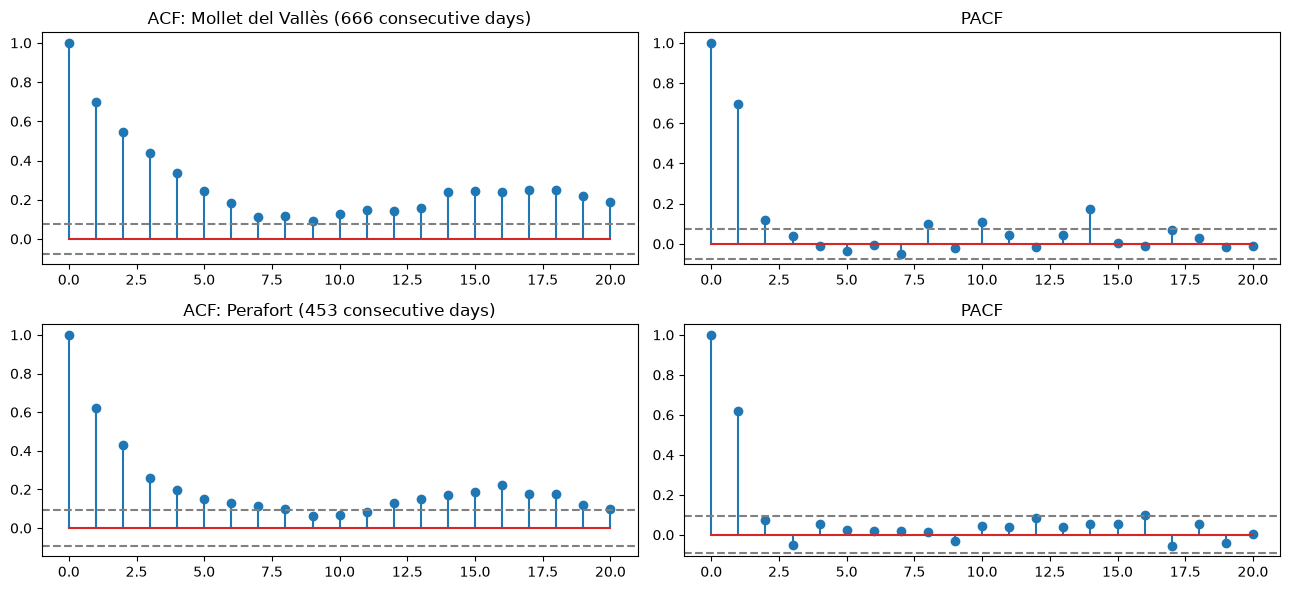

In [5]:
# classical ACF / PACF plot for the stations with the longest unbroken runs
best = tests.sort_values("run_days", ascending=False).head(2).index
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for i, s_ in enumerate(best):
    a, b, n = longest_run(panelP[s_].index); x = panelP[s_].loc[a:b, TARGET]
    ax[i, 0].stem(range(21), acf(x, nlags=20)); ax[i, 0].set_title(f"ACF: {s_} ({n} consecutive days)")
    ax[i, 1].stem(range(21), pacf(x, nlags=20)); ax[i, 1].set_title("PACF")
    for a_ in ax[i]: a_.axhline(1.96 / np.sqrt(n), ls="--", c="grey"); a_.axhline(-1.96 / np.sqrt(n), ls="--", c="grey")
show_fig()

**How to read it.** ACF bars outside the dashed band mean the value k days earlier still carries information; a slow decay means yesterday predicts today. The PACF removes the in-between days and suggests how many lags matter (and the AR order for ARIMA). **ADF**'s null hypothesis is "not stationary" (p < 0.05 means stationary). **Ljung-Box**'s null hypothesis is "no autocorrelation" (p < 0.05 means there is some).

## 5c. Target drift across months and years: median, IQR and high-concentration frequency

,median,iqr,share_gt25_pct,share_gt50_pct,n
date,,,,,
2016,7.07,6.80,1.60,0.00,312.0
2017,8.00,7.90,3.37,0.35,3178.0
2018,10.28,6.92,2.65,0.04,2562.0
2019,7.00,9.83,3.35,0.04,5038.0
2020,6.33,7.60,2.94,0.11,5543.0
2021,7.11,8.00,3.12,0.57,7949.0
2022,8.08,7.39,2.32,0.49,9440.0
2023,8.68,7.51,2.38,0.19,10793.0
2024,8.03,7.15,3.20,0.17,18368.0


date,1,2,3,4,5,6,7,8,9,10,11,12
median,8.77,9.54,7.87,6.73,6.83,8.29,8.55,9.67,7.06,7.56,7.70,9.00
iqr,9.00,9.39,7.86,6.40,5.84,7.23,6.83,7.73,6.49,7.18,8.12,9.54
share_gt25_pct,5.48,6.32,3.99,1.46,0.59,2.34,1.62,2.43,1.47,1.94,2.93,6.71
share_gt50_pct,0.45,0.43,0.58,0.18,0.13,0.10,0.18,0.15,0.22,0.13,0.27,0.30
n,7824.00,6710.00,7109.00,6762.00,6995.00,7130.00,6728.00,6663.00,6744.00,7168.00,7783.00,7746.00


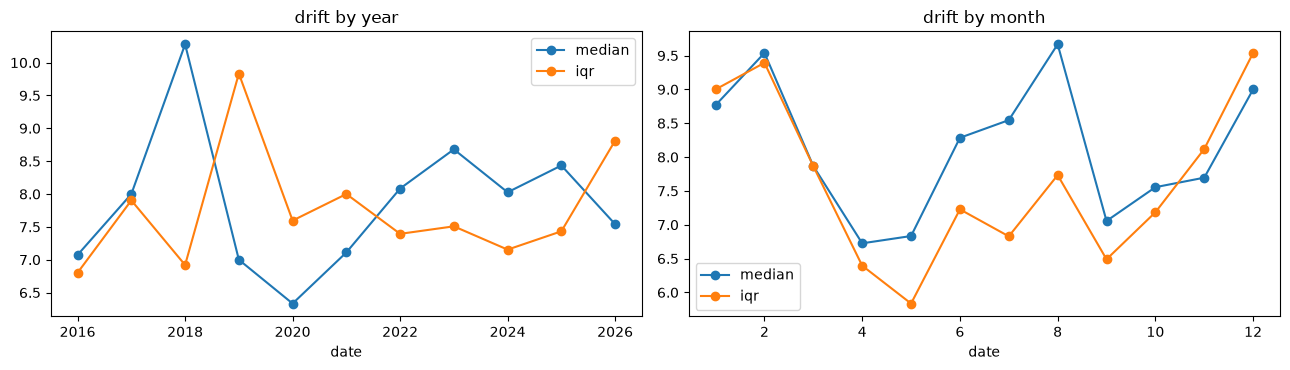

In [6]:
def drift(g):
    return pd.Series({"median": g.median(), "iqr": g.quantile(.75) - g.quantile(.25), "share_gt25_pct": (g > 25).mean() * 100,
                      "share_gt50_pct": (g > 50).mean() * 100, "n": len(g)})
by_year = P.groupby(P.date.dt.year)[TARGET].apply(drift).unstack()          # all valid target readings
by_month = P.groupby(P.date.dt.month)[TARGET].apply(drift).unstack()
display(by_year.round(2)); display(by_month.round(2).T)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
by_year[["median", "iqr"]].plot(marker="o", ax=ax[0], title="drift by year"); by_month[["median", "iqr"]].plot(marker="o", ax=ax[1], title="drift by month")
show_fig()

## 5d. Daily, monthly and seasonal patterns of PM2.5 and the atmospheric predictors

dow,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
median PM2.5 by weekday,7.82,8.0,8.21,8.3,8.19,8.03,7.73


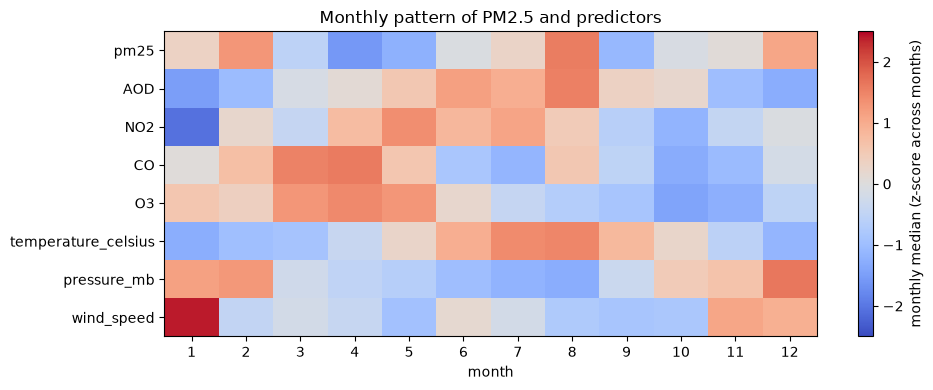

,pm25,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_speed
season,,,,,,,,
winter,8.83542,0.079,0.00008,0.03192,0.14500,10.79320,1002.00935,1.95055
spring,6.69524,0.133,0.00009,0.03337,0.15667,15.61010,996.65377,1.55267
summer,8.50000,0.168,0.00009,0.03076,0.13941,25.25549,994.98494,1.63372
autumn,7.36842,0.119,0.00008,0.03023,0.13193,18.60690,998.84883,1.63177


In [7]:
dow = P.assign(dow=P.date.dt.day_name()).groupby("dow")[TARGET].median().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
display(dow.round(2).to_frame("median PM2.5 by weekday").T)
pat_vars = [TARGET, "AOD"] + GAS + ["temperature_celsius", "pressure_mb", "wind_speed"]
monthly = df.groupby("month")[pat_vars].median()
z = (monthly - monthly.mean()) / monthly.std()
fig, ax = plt.subplots(figsize=(10, 4)); im_ = ax.imshow(z.T, aspect="auto", cmap="coolwarm", vmin=-2.5, vmax=2.5)
ax.set_yticks(range(len(pat_vars))); ax.set_yticklabels(pat_vars); ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13)); ax.set_xlabel("month")
plt.colorbar(im_, label="monthly median (z-score across months)"); ax.set_title("Monthly pattern of PM2.5 and predictors"); show_fig()
seasonal = df.groupby("season")[pat_vars].median().reindex(["winter", "spring", "summer", "autumn"])
display(seasonal.round(5))

## 5e. Lead-lag relationships between PM2.5 and AOD, NO2, CO, O3, wind and temperature

For each station of the modelling table (no gap crossing; needs the predictors, so it uses the matched data) we correlate PM2.5 on day *t* with the predictor on day *t - k*. **Positive k: the predictor comes first.** Values are Spearman correlations averaged over stations.

In [8]:
ll_vars = ["AOD", "NO2", "CO", "O3", "wind_speed", "temperature_celsius"]
lags = range(-3, 4)
elig_df = [s_ for s_, g in df.groupby("station_id") if len(g) >= 100]
ll = pd.DataFrame(index=ll_vars, columns=list(lags), dtype=float)
for x in ll_vars:
    for k in lags:
        r = []
        for s_ in elig_df:
            d_ = daily[s_]
            pair = pd.concat([d_[TARGET], d_[x].shift(k)], axis=1).dropna()
            if len(pair) >= 60: r.append(pair.corr(method="spearman").iloc[0, 1])
        ll.loc[x, k] = np.nanmean(r) if r else np.nan
display(ll.round(3))

,-3,-2,-1,0,1,2,3
AOD,0.100,0.132,0.193,0.216,0.133,0.071,0.066
NO2,0.064,0.067,0.124,0.274,0.259,0.179,0.130
CO,0.050,0.047,0.046,0.049,0.070,0.075,0.082
O3,-0.126,-0.130,-0.165,-0.207,-0.203,-0.154,-0.122
wind_speed,-0.074,-0.069,-0.124,-0.292,-0.291,-0.206,-0.144
temperature_celsius,0.110,0.110,0.131,0.086,0.085,0.065,0.053


## 5f. Decision gate

In [9]:
acf1 = float(acf_sum.loc[1, "50%"])
ac_share = float((tests.ljungbox_p_lag7 < .05).mean())
cover = float(regularity.coverage.median())
TEMPORAL_OK = acf1 > 0.3 and ac_share > 0.5
print(f"median lag-1 ACF across stations      : {acf1:.2f}  (rule: > 0.3)")
print(f"stations with Ljung-Box p < 0.05      : {ac_share*100:.0f}%  (rule: > 50%)")
print(f"median station coverage               : {cover*100:.0f}% of days between first and last reading")
print("\n=> temporal validation and lag/rolling features are", "APPROPRIATE" if TEMPORAL_OK else "NOT justified")
print("   Scenario: forecast PM2.5 for day t using information up to day t-1 (past PM2.5 allowed), with day-t")
print("   satellite/meteorological inputs. For same-day NOWCASTING, drop the past-PM2.5 features (FEATURES_NOWCAST in src/features.py).")

median lag-1 ACF across stations      : 0.65  (rule: > 0.3)
stations with Ljung-Box p < 0.05      : 99%  (rule: > 50%)
median station coverage               : 52% of days between first and last reading

=> temporal validation and lag/rolling features are APPROPRIATE
   Scenario: forecast PM2.5 for day t using information up to day t-1 (past PM2.5 allowed), with day-t
   satellite/meteorological inputs. For same-day NOWCASTING, drop the past-PM2.5 features (FEATURES_NOWCAST in src/features.py).


**Conclusion.** Strong day-to-day autocorrelation at almost every station: temporal validation and lag/rolling features are justified. Scenario: forecast PM2.5 for day *t* with information up to day *t-1* (past PM2.5 allowed) and day-*t* satellite/meteorological inputs. The features, folds and leakage-free preprocessing are built by `scripts/run_preprocessing.py`.